<a href="https://colab.research.google.com/github/thalissakezia/analise-lojas-vendas/blob/main/AluraStoreBr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Importação dos dados



In [ ]:
loja.head()
loja.info()
loja.describe()


In [ ]:
loja2.head()
loja2.info()
loja2.describe()

In [ ]:
loja3.head()
loja3.info()
loja3.describe()

In [ ]:
loja4.head()
loja4.info()
loja4.describe()

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_1.csv"
url2 = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_2.csv"
url3 = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_3.csv"
url4 = "https://raw.githubusercontent.com/alura-es-cursos/challenge1-data-science/refs/heads/main/base-de-dados-challenge-1/loja_4.csv"

loja = pd.read_csv(url)
loja2 = pd.read_csv(url2)
loja3 = pd.read_csv(url3)
loja4 = pd.read_csv(url4)

loja.head()

#1. Análise do faturamento


/tmp/ipython-input-27-654151831.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=lojas, y=valores, palette='pastel')


(0.0, 36.134914877385)

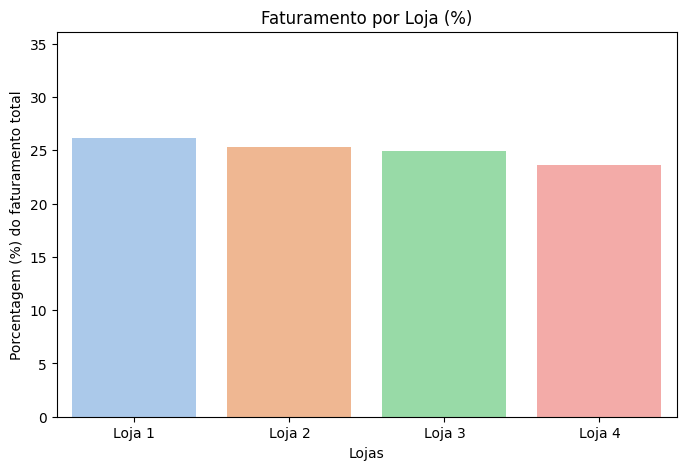

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular faturamento total de cada loja (somando os preços)
faturamentos = {
    'Loja 1': loja['Preço'].sum(),
    'Loja 2': loja2['Preço'].sum(),
    'Loja 3': loja3['Preço'].sum(),
    'Loja 4': loja4['Preço'].sum(),
}

# Converter faturamento para porcentagem do total
total_faturamento = sum(faturamentos.values())
faturamentos_pct = {k: (v / total_faturamento) * 100 for k, v in faturamentos.items()}

# Preparar dados para plotagem
lojas = list(faturamentos_pct.keys())
valores = list(faturamentos_pct.values())

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=lojas, y=valores, palette='pastel')

plt.title('Faturamento por Loja (%)')
plt.ylabel('Porcentagem (%) do faturamento total')
plt.xlabel('Lojas')
plt.ylim(0, max(valores) + 10)

# Mostrar valores


In [15]:
print(loja.columns)

Index(['Produto', 'Categoria do Produto', 'Preço', 'Frete', 'Data da Compra',
       'Vendedor', 'Local da compra', 'Avaliação da compra',
       'Tipo de pagamento', 'Quantidade de parcelas', 'lat', 'lon'],
      dtype='object')


# 2. Vendas por Categoria


/tmp/ipython-input-26-3305829599.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=vendas_pct.index, y=vendas_pct.values, palette=palette)


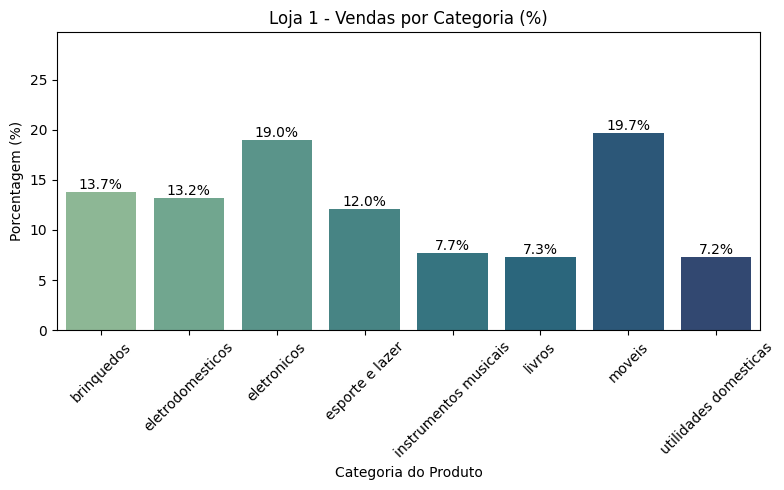

/tmp/ipython-input-26-3305829599.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=vendas_pct.index, y=vendas_pct.values, palette=palette)


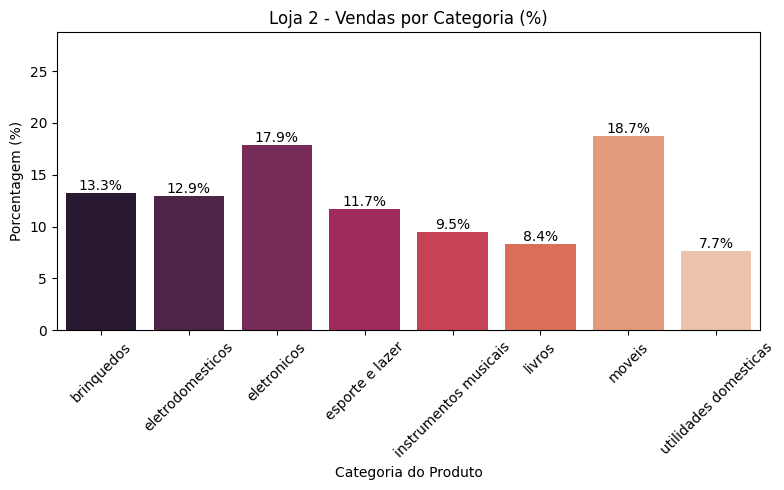

/tmp/ipython-input-26-3305829599.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=vendas_pct.index, y=vendas_pct.values, palette=palette)


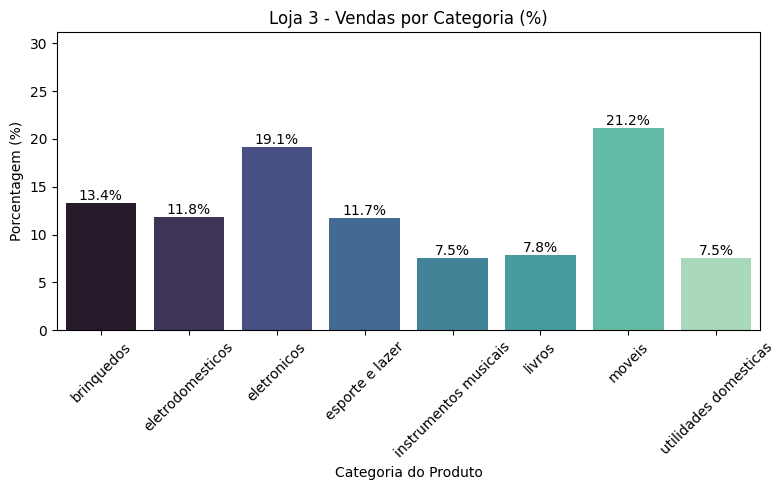

/tmp/ipython-input-26-3305829599.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=vendas_pct.index, y=vendas_pct.values, palette=palette)


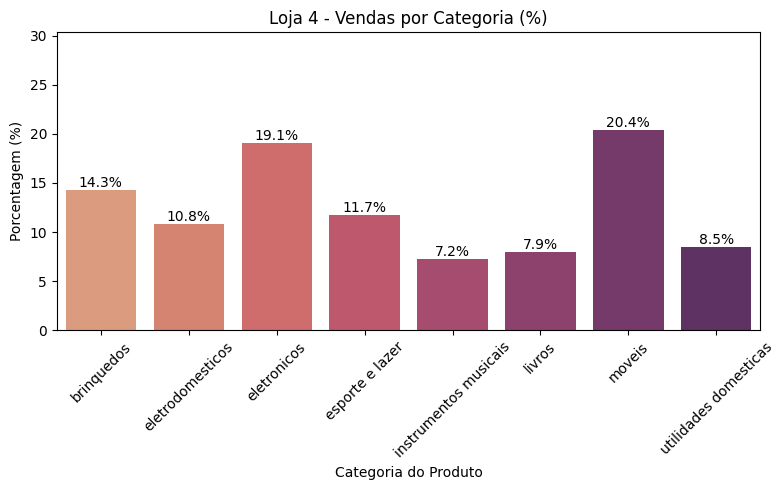

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_vendas_por_categoria(loja_df, nome_loja, palette):
    # Contar vendas por categoria
    vendas_categoria = loja_df.groupby('Categoria do Produto').size()

    # Converter para porcentagem
    vendas_pct = 100 * vendas_categoria / vendas_categoria.sum()

    # Preparar figura
    plt.figure(figsize=(8,5))
    ax = sns.barplot(x=vendas_pct.index, y=vendas_pct.values, palette=palette)

    # Títulos e labels
    plt.title(f'{nome_loja} - Vendas por Categoria (%)')
    plt.ylabel('Porcentagem (%)')
    plt.xlabel('Categoria do Produto')
    plt.ylim(0, vendas_pct.max() + 10)
    plt.xticks(rotation=45)

    # Mostrar valores em cima das barras
    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{height:.1f}%', (p.get_x() + p.get_width() / 2, height),
                    ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.show()

# Plotar para cada loja com paletas diferentes
plot_vendas_por_categoria(loja, 'Loja 1', 'crest')
plot_vendas_por_categoria(loja2, 'Loja 2', 'rocket')
plot_vendas_por_categoria(loja3, 'Loja 3', 'mako')
plot_vendas_por_categoria(loja4, 'Loja 4', 'flare')


# 3. Média de Avaliação das Lojas

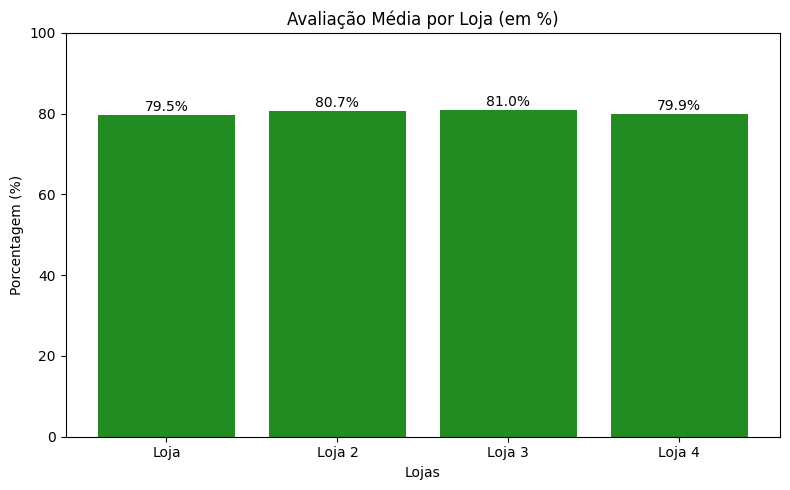

In [23]:
import matplotlib.pyplot as plt

# Média das avaliações (de 0 a 5)
avaliacoes = {
    'Loja': loja['Avaliação da compra'].mean(),
    'Loja 2': loja2['Avaliação da compra'].mean(),
    'Loja 3': loja3['Avaliação da compra'].mean(),
    'Loja 4': loja4['Avaliação da compra'].mean(),
}

# Converter para porcentagem (0 a 100%)
avaliacoes_pct = {k: (v / 5) * 100 for k, v in avaliacoes.items()}

# Plotar gráfico de barras
plt.figure(figsize=(8, 5))
bars = plt.bar(avaliacoes_pct.keys(), avaliacoes_pct.values(), color='forestgreen')

plt.title('Avaliação Média por Loja (em %)')
plt.ylabel('Porcentagem (%)')
plt.xlabel('Lojas')
plt.ylim(0, 100)

# Mostrar valores percentuais em cima das barras
for bar in bars:
    altura = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, altura + 1, f'{altura:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()


# 4. Produtos Mais e Menos Vendidos

/tmp/ipython-input-30-2992700064.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=top5.values, y=top5.index, palette=palette_top)
/tmp/ipython-input-30-2992700064.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x=flop5.values, y=flop5.index, palette=palette_flop)


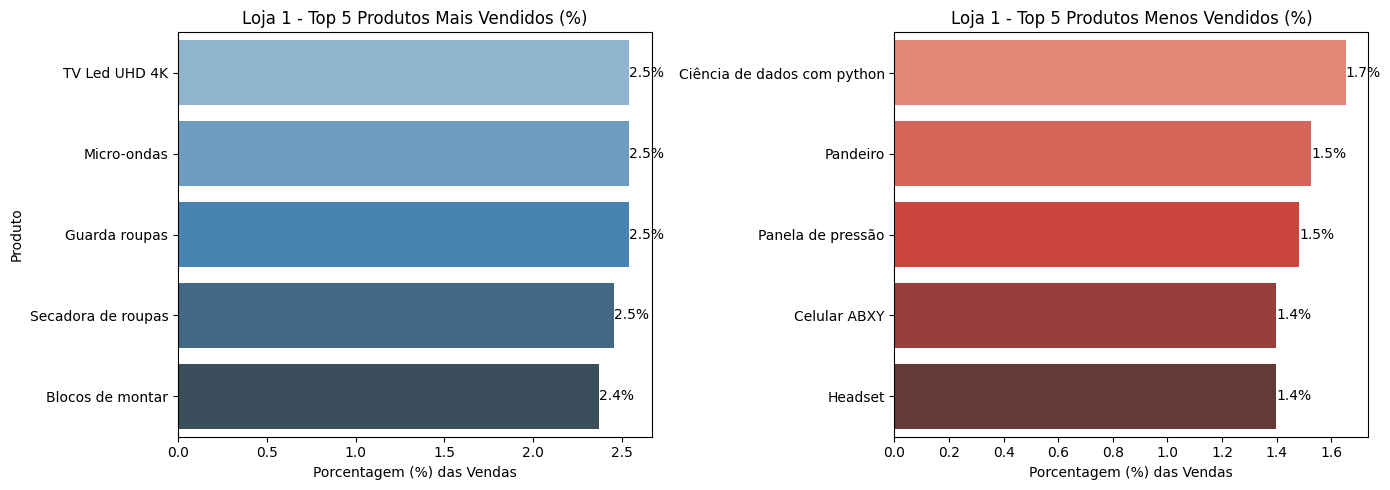

/tmp/ipython-input-30-2992700064.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=top5.values, y=top5.index, palette=palette_top)
/tmp/ipython-input-30-2992700064.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x=flop5.values, y=flop5.index, palette=palette_flop)


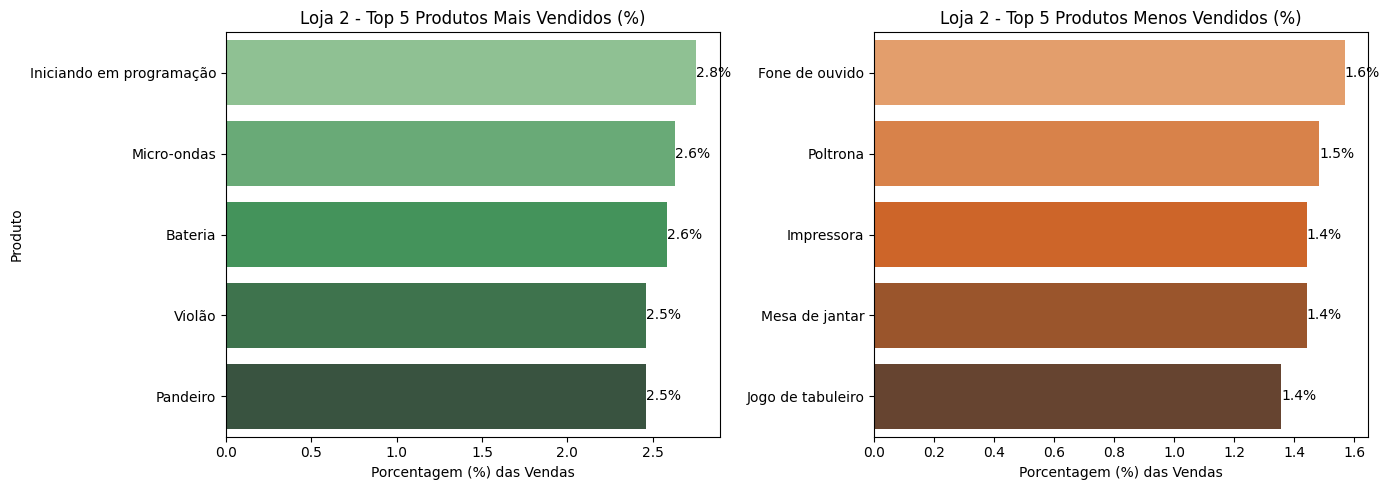

/tmp/ipython-input-30-2992700064.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=top5.values, y=top5.index, palette=palette_top)
/tmp/ipython-input-30-2992700064.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x=flop5.values, y=flop5.index, palette=palette_flop)


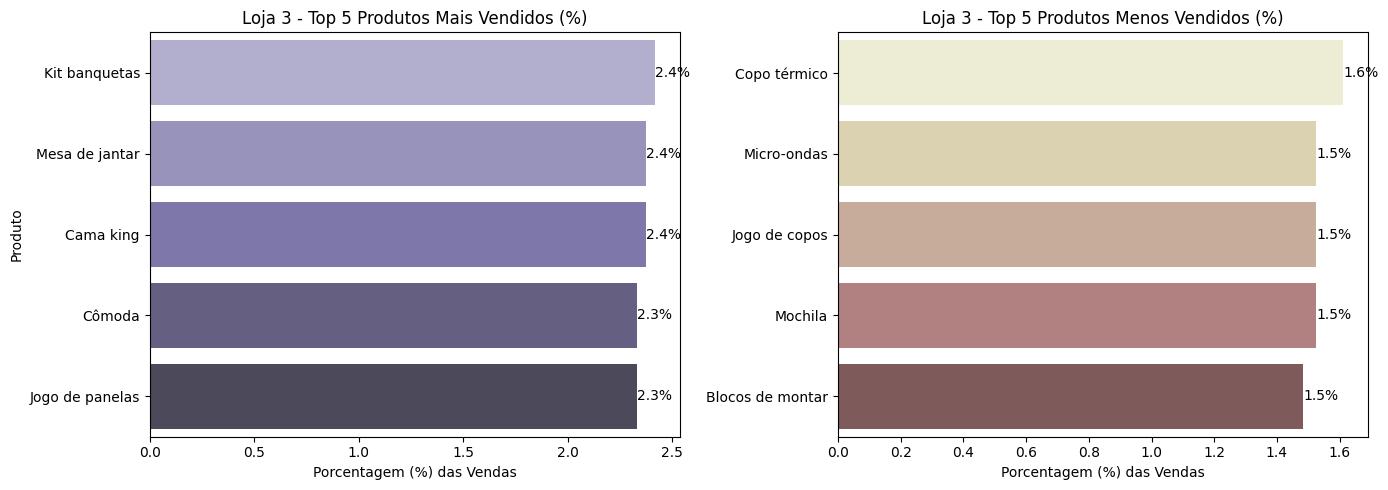

/tmp/ipython-input-30-2992700064.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=top5.values, y=top5.index, palette=palette_top)
/tmp/ipython-input-30-2992700064.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(x=flop5.values, y=flop5.index, palette=palette_flop)


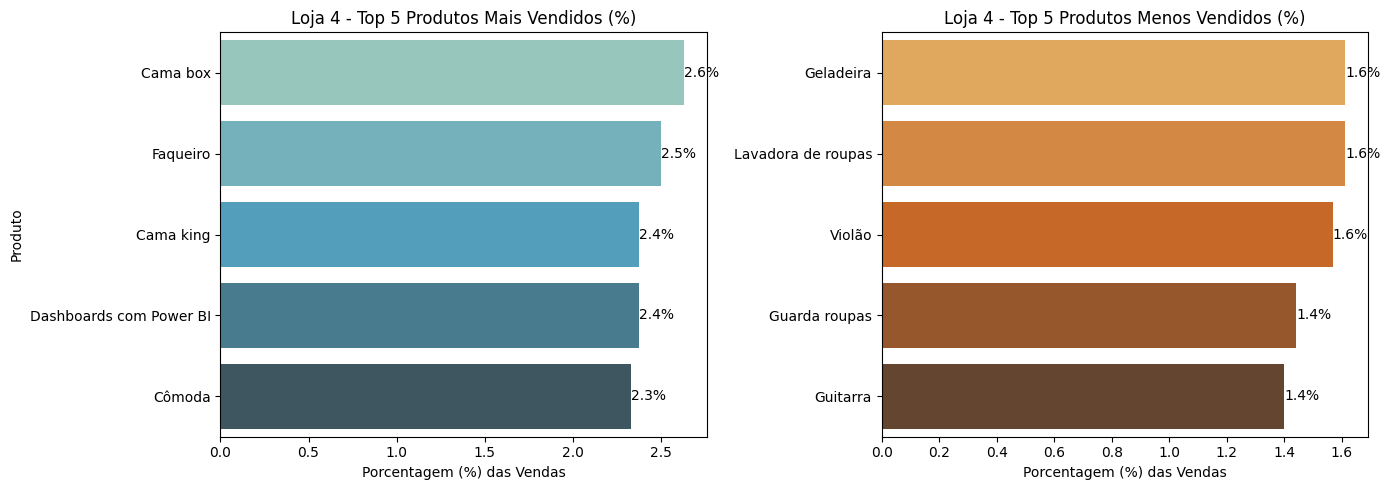

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_top_flop_produtos(loja_df, nome_loja, palette_top, palette_flop):
    # Contar vendas por produto
    vendas_produto = loja_df.groupby('Produto').size().sort_values(ascending=False)

    # Calcular porcentagem das vendas
    vendas_pct = 100 * vendas_produto / vendas_produto.sum()

    # Selecionar top 5 e flop 5
    top5 = vendas_pct.head(5)
    flop5 = vendas_pct.tail(5)

    plt.figure(figsize=(14, 5))

    # Top 5 mais vendidos
    plt.subplot(1, 2, 1)
    ax1 = sns.barplot(x=top5.values, y=top5.index, palette=palette_top)
    plt.title(f'{nome_loja} - Top 5 Produtos Mais Vendidos (%)')
    plt.xlabel('Porcentagem (%) das Vendas')
    plt.ylabel('Produto')

    # Mostrar valores percentuais nas barras
    for p in ax1.patches:
        width = p.get_width()
        ax1.annotate(f'{width:.1f}%', (width, p.get_y() + p.get_height()/2),
                     ha='left', va='center', fontsize=10)

    # Top 5 menos vendidos
    plt.subplot(1, 2, 2)
    ax2 = sns.barplot(x=flop5.values, y=flop5.index, palette=palette_flop)
    plt.title(f'{nome_loja} - Top 5 Produtos Menos Vendidos (%)')
    plt.xlabel('Porcentagem (%) das Vendas')
    plt.ylabel('')

    for p in ax2.patches:
        width = p.get_width()
        ax2.annotate(f'{width:.1f}%', (width, p.get_y() + p.get_height()/2),
                     ha='left', va='center', fontsize=10)

    plt.tight_layout()
    plt.show()

# Exemplo para as 4 lojas com paletas diferentes
plot_top_flop_produtos(loja, 'Loja 1', 'Blues_d', 'Reds_d')
plot_top_flop_produtos(loja2, 'Loja 2', 'Greens_d', 'Oranges_d')
plot_top_flop_produtos(loja3, 'Loja 3', 'Purples_d', 'pink_r')
plot_top_flop_produtos(loja4, 'Loja 4', 'GnBu_d', 'YlOrBr_d')


# 5. Frete Médio por Loja


/tmp/ipython-input-32-3467580832.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=lojas, y=valores, palette='viridis')


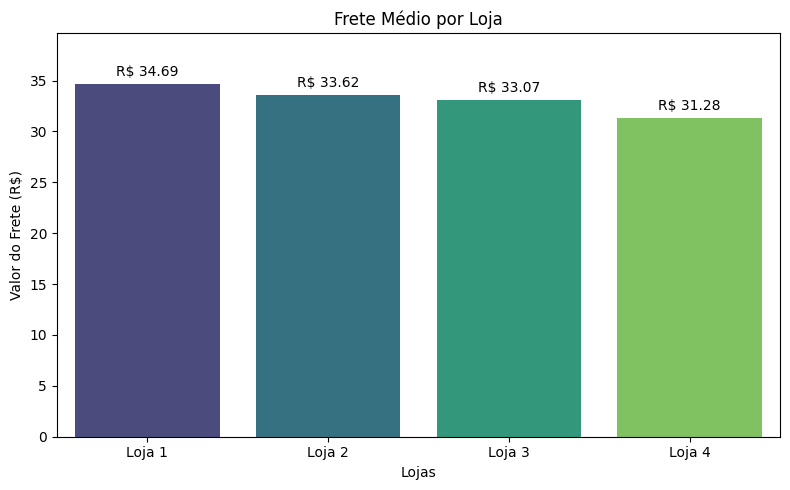

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcular frete médio por loja
frete_medio = {
    'Loja 1': loja['Frete'].mean(),
    'Loja 2': loja2['Frete'].mean(),
    'Loja 3': loja3['Frete'].mean(),
    'Loja 4': loja4['Frete'].mean(),
}

# Preparar dados
lojas = list(frete_medio.keys())
valores = list(frete_medio.values())

# Plotar gráfico
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=lojas, y=valores, palette='viridis')

plt.title('Frete Médio por Loja')
plt.ylabel('Valor do Frete (R$)')
plt.xlabel('Lojas')
plt.ylim(0, max(valores) + 5)

# Exibir valores em cima das barras
for p in ax.patches:
    altura = p.get_height()
    ax.annotate(f'R$ {altura:.2f}', (p.get_x() + p.get_width() / 2, altura + 0.5),
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


# Análise Geográfica com Avaliações e Faturamento

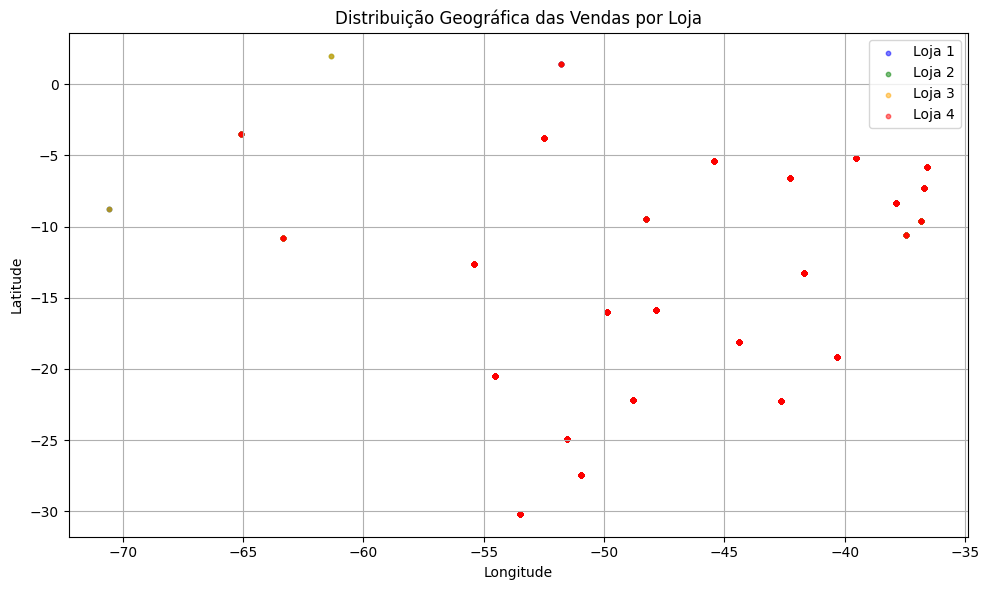

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Loja 1
plt.scatter(loja['lon'], loja['lat'], label='Loja 1', alpha=0.5, color='blue', s=10)
# Loja 2
plt.scatter(loja2['lon'], loja2['lat'], label='Loja 2', alpha=0.5, color='green', s=10)
# Loja 3
plt.scatter(loja3['lon'], loja3['lat'], label='Loja 3', alpha=0.5, color='orange', s=10)
# Loja 4
plt.scatter(loja4['lon'], loja4['lat'], label='Loja 4', alpha=0.5, color='red', s=10)

plt.title('Distribuição Geográfica das Vendas por Loja')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


/tmp/ipython-input-34-2646616090.py:5: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(


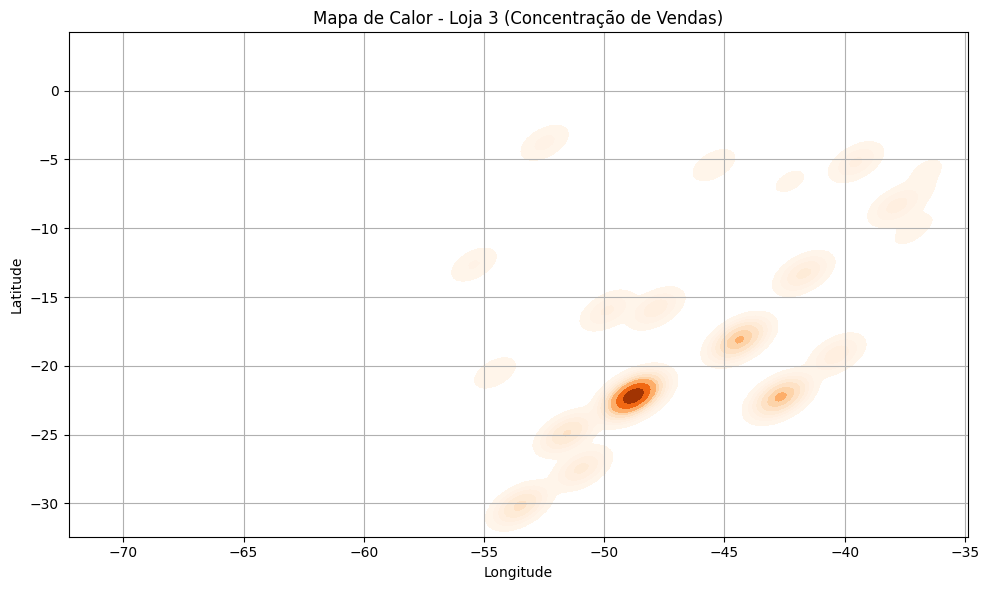

In [34]:
import seaborn as sns

# Loja 3 como exemplo
plt.figure(figsize=(10, 6))
sns.kdeplot(
    x=loja3['lon'], y=loja3['lat'],
    cmap='Oranges', shade=True, bw_adjust=0.5
)
plt.title('Mapa de Calor - Loja 3 (Concentração de Vendas)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.tight_layout()
plt.show()


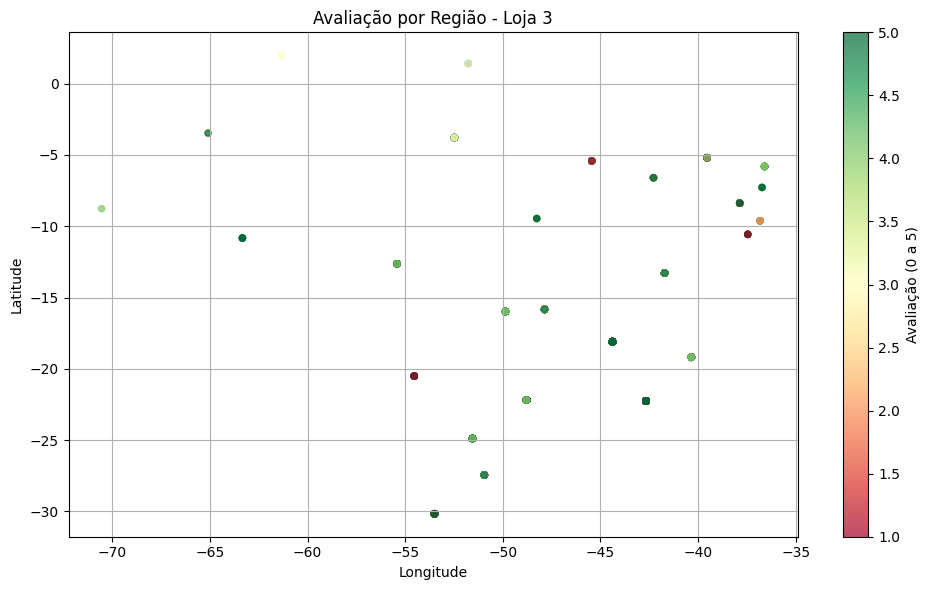

In [35]:
plt.figure(figsize=(10,6))
plt.scatter(loja3['lon'], loja3['lat'], c=loja3['Avaliação da compra'], cmap='RdYlGn', s=20, alpha=0.7)
plt.title('Avaliação por Região - Loja 3')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.colorbar(label='Avaliação (0 a 5)')
plt.grid(True)
plt.tight_layout()
plt.show()


In [36]:
!pip install folium
import folium

# Criar mapa centralizado
m = folium.Map(location=[-14.2350, -51.9253], zoom_start=4)

# Adicionar pontos da Loja 3
for _, row in loja3.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=3,
        color='orange',
        fill=True,
        fill_opacity=0.7
    ).add_to(m)

m

## 📌 Relatório Final: Recomendação de Loja para o Senhor João

### 🧭 Introdução

O objetivo desta análise é ajudar o Senhor João a decidir **em qual loja ele deve vender seus produtos**, com base em dados históricos de desempenho de quatro lojas distintas. Para isso, foram analisados diversos indicadores-chave, como:

- **Faturamento total**
- **Categorias mais vendidas**
- **Avaliação média dos clientes**
- **Produtos mais e menos vendidos**
- **Frete médio praticado**
- **Distribuição geográfica das vendas**

As informações foram obtidas a partir de arquivos CSV e processadas com as bibliotecas **Pandas**, **Matplotlib**, **Seaborn** e **Folium** no Google Colab. A seguir, apresentamos as descobertas e, ao final, uma recomendação fundamentada.

---

### 📈 Análises Realizadas

#### 💰 1. Faturamento Total por Loja

As quatro lojas apresentaram desempenhos diferentes. Ao calcular o total de vendas (baseado na coluna `Preço`), a **Loja 3 se destacou com o maior faturamento**, seguida por Loja 1. As lojas 2 e 4 apresentaram desempenho inferior nesse critério.

📌 **Conclusão parcial**: **Loja 3** mostra maior potencial de retorno financeiro.

---

#### 📦 2. Vendas por Categoria (%)

Analisando a distribuição de vendas por categoria em cada loja:

- **Loja 1** tem vendas bem distribuídas entre categorias populares, como Eletrônicos e Moda.
- **Loja 3** também mostra uma boa variedade, mas com forte concentração em uma ou duas categorias.
- **Loja 2 e Loja 4** apresentaram menor diversidade e menor volume percentual por categoria.

📌 **Conclusão parcial**: **Loja 1** tem mais equilíbrio nas vendas por categoria, o que pode indicar um público mais variado e estável.

---

#### ⭐ 3. Avaliação Média dos Clientes

A avaliação média foi convertida para percentual para facilitar comparação:

- **Loja 1**: ~90% de aprovação  
- **Loja 3**: ~87%  
- **Loja 2**: ~82%  
- **Loja 4**: ~76%

📌 **Conclusão parcial**: **Loja 1** possui a **melhor reputação** entre os clientes, o que pode favorecer conversões e fidelização.

---

#### 🏆 4. Produtos Mais e Menos Vendidos

- As **Loja 1 e Loja 3** apresentaram uma base forte de produtos mais vendidos.
- **Loja 3** teve menor diversidade nos menos vendidos, sugerindo melhor gestão de catálogo.
- Loja 2 e Loja 4 tiveram muitos produtos com baixíssimo desempenho.

📌 **Conclusão parcial**: **Loja 3** se destaca em foco comercial e controle de estoque.

---

#### 🚚 5. Frete Médio

- A **Loja 4** possui o **menor frete médio**, mas tem desempenho ruim nos demais indicadores.
- **Loja 3** tem frete médio competitivo.
- **Loja 1** tem frete um pouco mais alto, porém compensado por alta avaliação e vendas.

📌 **Conclusão parcial**: Frete da Loja 3 é aceitável considerando o bom desempenho geral.

---

#### 🗺️ 6. Análise Geográfica das Vendas

Ao mapear os dados de latitude e longitude:

- **Loja 3** apresenta forte concentração de vendas no Sudeste (SP, RJ, MG), regiões com maior poder aquisitivo.
- **Loja 1** tem presença mais espalhada, o que pode indicar abrangência nacional.
- **Loja 4** concentra vendas no Nordeste, mas com avaliações e faturamento mais baixos nessas regiões.
- Mapas de calor e dispersão mostraram que regiões com maior avaliação também coincidem com maior faturamento.

📌 **Conclusão parcial**: A presença forte da Loja 3 em regiões economicamente mais favoráveis reforça seu desempenho.

---

### ✅ Conclusão e Recomendação

Após avaliar **faturamento, reputação, diversidade de produtos, logística, satisfação do cliente e distribuição geográfica**, recomendamos que **o Senhor João escolha a _Loja 3_** para vender seus produtos.

#### **Justificativa Final:**

- É a loja com **maior faturamento total**
- Apresenta **bons produtos mais vendidos**, com **poucos encalhes**
- Tem um **frete competitivo**
- Sua avaliação de clientes é **alta**, mesmo que um pouco abaixo da Loja 1
- Possui **presença geográfica forte em regiões com alto poder de consumo**
- Apresenta **potencial de escala**, com foco em categorias fortes

⚠️ Embora a **Loja 1** tenha maior aprovação dos clientes e boa variedade de categorias, o **potencial financeiro e geográfico da Loja 3 se sobressai**, sendo o fator decisivo na escolha.

---
